### After cleaning the car dataset, I decided to use `Linear Regression` for prediction.

To use this algorithm properly, I need to check some assumptions and make sure they are satisfied so that the model can perform well.

Because I know that the `Linear Regression` algorithm works best when the relationship between the features and the target column is approximately linear.

I do not need to focus much on the categorical columns because they will later be converted into dummy variables.

The main focus is on the numerical columns such as `Mileage`, `EngineV`, and `Year`.

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set() # all plot will cover on seaborn style

In [2]:
# loading the data
car = pd.read_csv("Data/Car_cleaned.csv")

In [3]:
car.head()

,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year
0,BMW,4200.0,sedan,277,2.0,Petrol,yes,1991
1,Mercedes-Benz,7900.0,van,427,2.9,Diesel,yes,1999
2,Mercedes-Benz,13300.0,sedan,358,5.0,Gas,yes,2003
3,Audi,23000.0,crossover,240,4.2,Petrol,yes,2007
4,Toyota,18300.0,crossover,120,2.0,Petrol,yes,2011


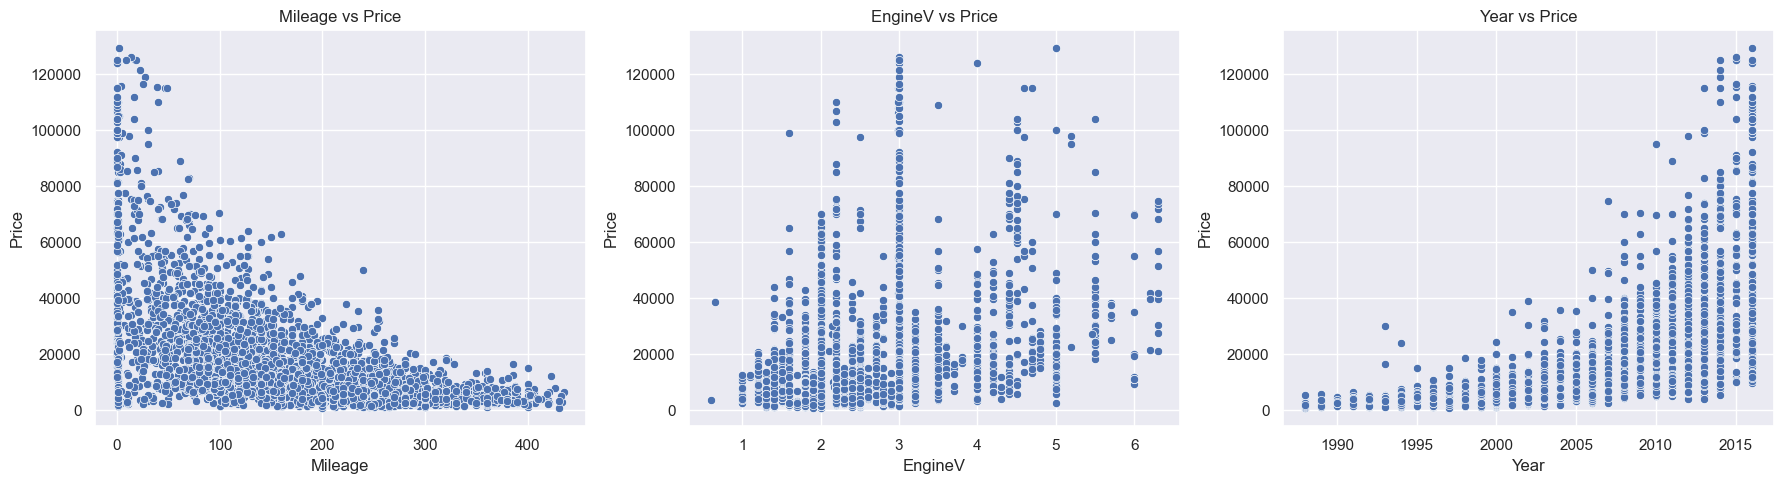

In [4]:
# Plotting all the three numerical columns
plt.figure(figsize=(18,5))

plt.subplot(1,3,1)
sns.scatterplot(x=car['Mileage'], y=car['Price'])
plt.title("Mileage vs Price")

plt.subplot(1,3,2)
sns.scatterplot(x=car['EngineV'], y=car['Price'])
plt.title("EngineV vs Price")

plt.subplot(1,3,3)
sns.scatterplot(x=car['Year'], y=car['Price'])
plt.title("Year vs Price")

plt.tight_layout()

#### Now I can see that the relation is anything but not linear. I can not run `Linear Regression` in here.

I have to transform these column

<Axes: xlabel='Price', ylabel='Count'>

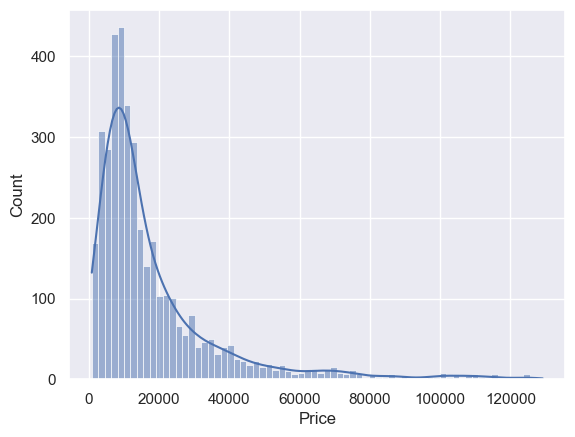

In [5]:
# checking the price
sns.histplot(car['Price'], kde=True)

- The problem lies with the price, the price we have in the data is not linear.

- Common approch form many others to transform the data is `log transformation`.

- `np.log(x)` is a NumPy function that calculates the **natural logarithm** of a number or an array.


In [6]:
# transfor the price
log_price = np.log(car['Price'])

# adding another column 
car['log_price'] = log_price

# checking the data again
car.head()

,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year,log_price
0,BMW,4200.0,sedan,277,2.0,Petrol,yes,1991,8.342840
1,Mercedes-Benz,7900.0,van,427,2.9,Diesel,yes,1999,8.974618
2,Mercedes-Benz,13300.0,sedan,358,5.0,Gas,yes,2003,9.495519
3,Audi,23000.0,crossover,240,4.2,Petrol,yes,2007,10.043249
4,Toyota,18300.0,crossover,120,2.0,Petrol,yes,2011,9.814656


### `Log transformation` compresses large values and makes the distribution more balanced.

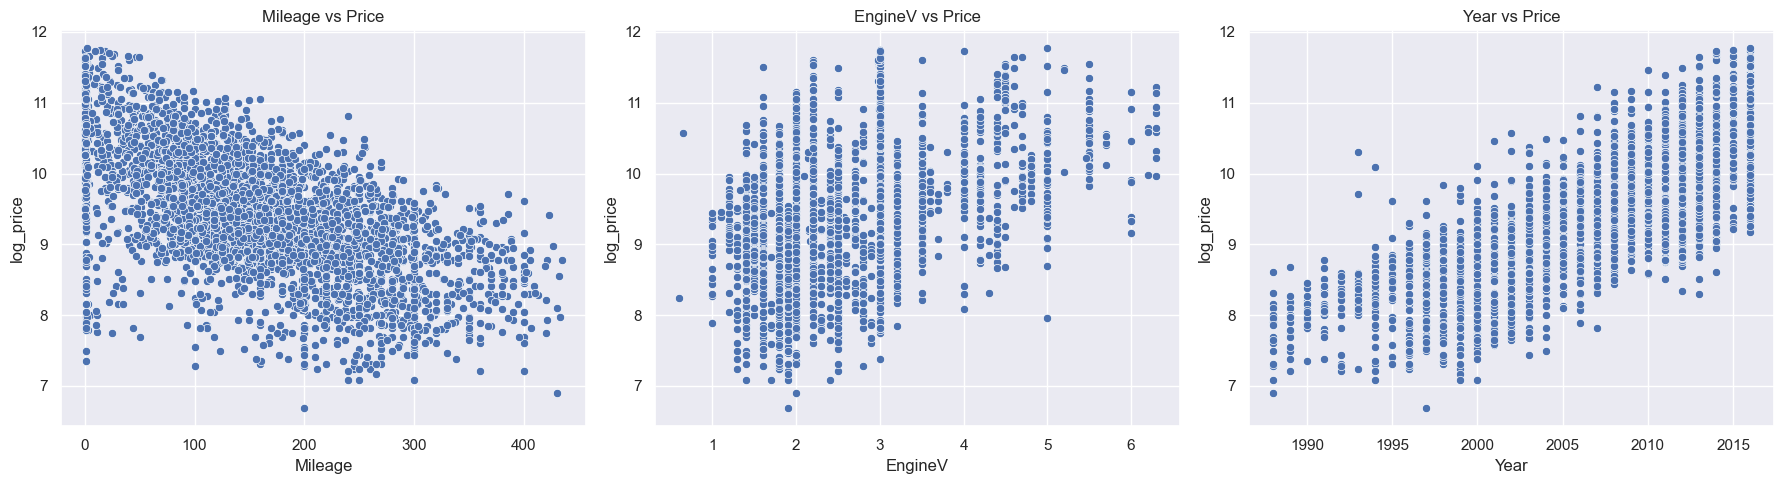

In [7]:
# plotting all the three numerical columns again with log price
plt.figure(figsize=(18,5))

plt.subplot(1,3,1)
sns.scatterplot(x=car['Mileage'], y=car['log_price'])
plt.title("Mileage vs Price")

plt.subplot(1,3,2)
sns.scatterplot(x=car['EngineV'], y=car['log_price'])
plt.title("EngineV vs Price")

plt.subplot(1,3,3)
sns.scatterplot(x=car['Year'], y=car['log_price'])
plt.title("Year vs Price")

plt.tight_layout()

### Now the whole picture change. 
- Here I can observe the linearity of the data with Price column

In [8]:
# droping the Original price column that is no longer needed
car = car.drop('Price', axis=1)

In [9]:
car.head()

,Brand,Body,Mileage,EngineV,Engine Type,Registration,Year,log_price
0,BMW,sedan,277,2.0,Petrol,yes,1991,8.342840
1,Mercedes-Benz,van,427,2.9,Diesel,yes,1999,8.974618
2,Mercedes-Benz,sedan,358,5.0,Gas,yes,2003,9.495519
3,Audi,crossover,240,4.2,Petrol,yes,2007,10.043249
4,Toyota,crossover,120,2.0,Petrol,yes,2011,9.814656


Up to Now 

* The data have linar relation with target column.
* This is almost normally distributed, that is I take care in previous car cleaning process by taking 99th percentile.

---
## Now check the Multicollinearity

Multicollinearity occurs when the feature of the data is corealeted with other feature.


In [10]:
car.columns

Index(['Brand', 'Body', 'Mileage', 'EngineV', 'Engine Type', 'Registration',
       'Year', 'log_price'],
      dtype='object')

<Axes: >

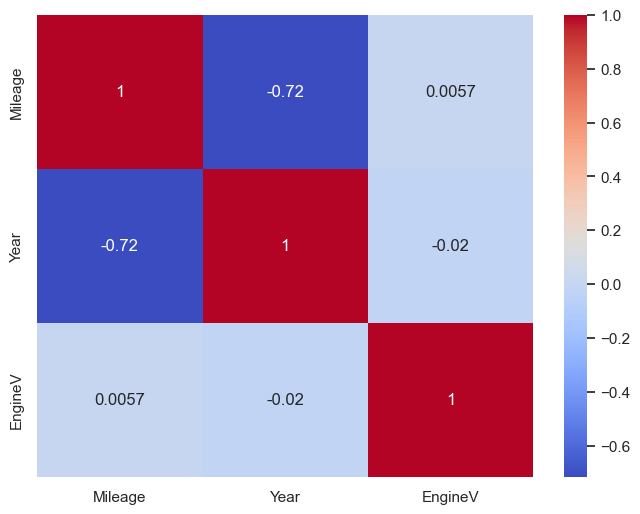

In [11]:
# Co-relation Heatmap
columns = ['Mileage', 'Year', 'EngineV']

corr_matrix = car[columns].corr()

plt.figure(figsize=(8,6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm"
)

#### The correlation heatmap helps to understand the relationship between numerical variables.
For example, Mileage and Year have a strong negative correlation (-0.72), meaning newer cars have lower mileage.

I will use the `VIF` or `Variance Inflation Factor` to check the multicollinearity.

The `VIF` produces a measure which estimates how much larger the square root of the standard error of the estimate is compared to a situation where the variable is completely uncorrelated with the other features.

In [12]:
# import VIF from statsmodels
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

# taking only numerical column beacuse the categorical will be converted as dummy variable
var = car[['Mileage', 'Year', 'EngineV']]  # '[[]]' select multiple columns,This returns a DataFrame (2D table).


# craating a dataframe
vif_df = pd.DataFrame()

# adding column
vif_df['VIF'] = [vif(var.values, i) for i in range(var.shape[1])] 
vif_df['features'] = var.columns

# checking the result
vif_df

,VIF,features
0,3.791584,Mileage
1,10.354854,Year
2,7.662068,EngineV


var.values - This converts the dataframe into a matrix (array).

Example, (1000, 3)
var.shape[0] → number of rows  , there are 1000 rows.
var.shape[1] → (Result 0,1,2) number of columns , Because there are 3 columns.

vif(var.values,0) → VIF of Mileage
vif(var.values,1) → VIF of Year
vif(var.values,2) → VIF of EngineV

#### Now here how it works.

When there is result `1` that means No correlation,  this is also the minimum value of the measure. but it has no upper limit.

Generaly the values are between `1 to 5` or `1< VIF < 5` are consider ok, but it is depend on the problem on hand and the devoloper. He/She will decied the cut-off value from his past experience.

From the result I have got look like the `Year` column is too much corelated with other column. and it will down others feature values. it will be good to drop down the year column.


In [13]:
# Drop the year column
car = car.drop('Year', axis=1)

In [14]:
car.head()

,Brand,Body,Mileage,EngineV,Engine Type,Registration,log_price
0,BMW,sedan,277,2.0,Petrol,yes,8.342840
1,Mercedes-Benz,van,427,2.9,Diesel,yes,8.974618
2,Mercedes-Benz,sedan,358,5.0,Gas,yes,9.495519
3,Audi,crossover,240,4.2,Petrol,yes,10.043249
4,Toyota,crossover,120,2.0,Petrol,yes,9.814656


## Now taking care about categorical columns

`Brand`, `Body`, `Engine Type` and `Registration`

In [15]:
# checking the datatypes
car.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3867 entries, 0 to 3866
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         3867 non-null   object 
 1   Body          3867 non-null   object 
 2   Mileage       3867 non-null   int64  
 3   EngineV       3867 non-null   float64
 4   Engine Type   3867 non-null   object 
 5   Registration  3867 non-null   object 
 6   log_price     3867 non-null   float64
dtypes: float64(2), int64(1), object(4)
memory usage: 211.6+ KB


- I will use `pandas` `.get_dummies()` method for this it will create a new column for all the categorical values.It will increase the dimention of the data.

In [16]:
car_dum = pd.get_dummies(car, dtype=int, drop_first=True) 

In [17]:
car_dum.head()

,Mileage,EngineV,log_price,Brand_BMW,Brand_Mercedes-Benz,Brand_Mitsubishi,Brand_Renault,Brand_Toyota,Brand_Volkswagen,Body_hatch,Body_other,Body_sedan,Body_vagon,Body_van,Engine Type_Gas,Engine Type_Other,Engine Type_Petrol,Registration_yes
0,277,2.0,8.342840,1,0,0,0,0,0,0,0,1,0,0,0,0,1,1
1,427,2.9,8.974618,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1
2,358,5.0,9.495519,0,1,0,0,0,0,0,0,1,0,0,1,0,0,1
3,240,4.2,10.043249,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1
4,120,2.0,9.814656,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1


In [20]:
# Checking the Multicolinearity for all coumns

# craating a dataframe
vif_df_all = pd.DataFrame()

# adding column
vif_df_all['VIF'] = [vif(car_dum.values, i) for i in range(car_dum.shape[1])]
vif_df_all['features'] = car_dum.columns

# checking the result
vif_df_all

,VIF,features
0,4.460434,Mileage
1,13.445639,EngineV
2,41.981260,log_price
3,2.603990,Brand_BMW
4,3.084356,Brand_Mercedes-Benz
5,1.830297,Brand_Mitsubishi
6,2.281498,Brand_Renault
7,2.406546,Brand_Toyota
8,3.312814,Brand_Volkswagen
9,1.583516,Body_hatch


This is very good result.
All the values are under 5 but the `log_price` or target column have `42` VIF value, that is telling us the price is highely 
corellated with other column, and this is very good sign.

#### Rearrange the column

In [21]:
car_dum.columns

Index(['Mileage', 'EngineV', 'log_price', 'Brand_BMW', 'Brand_Mercedes-Benz',
       'Brand_Mitsubishi', 'Brand_Renault', 'Brand_Toyota', 'Brand_Volkswagen',
       'Body_hatch', 'Body_other', 'Body_sedan', 'Body_vagon', 'Body_van',
       'Engine Type_Gas', 'Engine Type_Other', 'Engine Type_Petrol',
       'Registration_yes'],
      dtype='object')

In [22]:
# creating new arranged column
col = ['log_price', 'Mileage', 'EngineV', 'Brand_BMW', 'Brand_Mercedes-Benz',
       'Brand_Mitsubishi', 'Brand_Renault', 'Brand_Toyota', 'Brand_Volkswagen',
       'Body_hatch', 'Body_other', 'Body_sedan', 'Body_vagon', 'Body_van',
       'Engine Type_Gas', 'Engine Type_Other', 'Engine Type_Petrol',
       'Registration_yes']

# creating new data frame
car_pos = car_dum[col]
car_pos

,log_price,Mileage,EngineV,Brand_BMW,Brand_Mercedes-Benz,Brand_Mitsubishi,Brand_Renault,Brand_Toyota,Brand_Volkswagen,Body_hatch,Body_other,Body_sedan,Body_vagon,Body_van,Engine Type_Gas,Engine Type_Other,Engine Type_Petrol,Registration_yes
0,8.342840,277,2.0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,1
1,8.974618,427,2.9,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1
2,9.495519,358,5.0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,1
3,10.043249,240,4.2,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1
4,9.814656,120,2.0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3862,9.350102,163,2.5,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1
3863,9.792556,35,1.6,0,0,0,0,1,0,0,0,1,0,0,0,0,1,1
3864,11.736069,9,3.0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1
3865,8.779557,1,3.5,1,0,0,0,0,0,0,0,1,0,0,0,0,1,1


In [23]:
# saving the last preprocces data in csv file for model creating
car_pos.to_csv('Data/Car_preproccesed.csv', index=False)

print("Data saved...")

Data saved...


#### Here the data preprocessing and EDA is over.